In [ ]:
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# 1. Activation function & its derivative
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    # Note: 'x' here is assumed to already be the output of the sigmoid function
    return x * (1 - x)

# 2. Define the training dataset (XOR)
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([
    [0],
    [1],
    [1],
    [0]
])

# 3. Initialize network architecture & weights
input_size = 2
hidden_size = 3
output_size = 1

# Weights and Biases
# Hidden layer
W1 = np.random.uniform(size=(input_size, hidden_size))
b1 = np.zeros((1, hidden_size))

# Output layer
W2 = np.random.uniform(size=(hidden_size, output_size))
b2 = np.zeros((1, output_size))

learning_rate = 0.5
epochs = 10000

In [ ]:
# Track losses over time
losses = []

for epoch in range(epochs):
    # === FORWARD PROPAGATION ===
    # Input to Hidden layer
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)

    # Hidden layer to Output layer
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)  # Final prediction

    # Calculate loss (Mean Squared Error)
    loss = np.mean((y - a2) ** 2)
    losses.append(loss)

    # === BACKWARD PROPAGATION ===
    # Error at output layer
    error_output = y - a2
    d_output = error_output * sigmoid_derivative(a2)

    # Error at hidden layer
    error_hidden = d_output.dot(W2.T)
    d_hidden = error_hidden * sigmoid_derivative(a1)

    # === PARAMETER UPDATES ===
    W2 += a1.T.dot(d_output) * learning_rate
    b2 += np.sum(d_output, axis=0, keepdims=True) * learning_rate

    W1 += X.T.dot(d_hidden) * learning_rate
    b1 += np.sum(d_hidden, axis=0, keepdims=True) * learning_rate

    # Print progress every 1000 epochs
    if epoch % 1000 == 0:
        print(f"Epoch {epoch}/{epochs} - Loss: {loss:.6f}")

print(f"Final Epoch Loss: {losses[-1]:.6f}")

Epoch 0/10000 - Loss: 0.297848
Epoch 1000/10000 - Loss: 0.019149
Epoch 2000/10000 - Loss: 0.002749
Epoch 3000/10000 - Loss: 0.001358
Epoch 4000/10000 - Loss: 0.000883
Epoch 5000/10000 - Loss: 0.000648
Epoch 6000/10000 - Loss: 0.000510
Epoch 7000/10000 - Loss: 0.000419
Epoch 8000/10000 - Loss: 0.000355
Epoch 9000/10000 - Loss: 0.000307
Final Epoch Loss: 0.000271


In [ ]:
# Final Forward Pass
z1 = np.dot(X, W1) + b1
a1 = sigmoid(z1)
z2 = np.dot(a1, W2) + b2
predictions = sigmoid(z2)

print("Input:")
print(X)
print("\nActual Output:")
print(y)
print("\nPredicted Output:")
print(np.round(predictions, 4))

Input:
[[0 0]
 [0 1]
 [1 0]
 [1 1]]

Actual Output:
[[0]
 [1]
 [1]
 [0]]

Predicted Output:
[[0.0193]
 [0.9845]
 [0.9845]
 [0.0152]]


### Phase 1: Data Acquisition & Preprocessing

In this section, we will load the classic MNIST dataset of handwritten digits using `torchvision`. We will transform the images into PyTorch Tensors and normalize them to ensure stable gradients during training.

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# Define the transformations: Convert to tensor and normalize
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Download and load the training and test datasets
train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Set up DataLoader for batching
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Training set size: {len(train_dataset)}")
print(f"Test set size: {len(test_dataset)}")

100%|██████████| 9.91M/9.91M [00:01<00:00, 6.08MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 160kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.33MB/s]

Training set size: 60000
Test set size: 10000


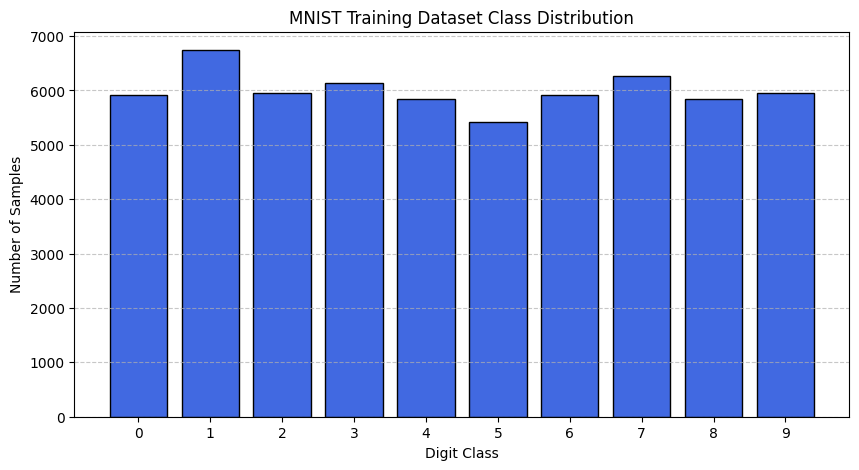

Class distribution percentages:
Digit 0: 5923 samples (9.87%)
Digit 1: 6742 samples (11.24%)
Digit 2: 5958 samples (9.93%)
Digit 3: 6131 samples (10.22%)
Digit 4: 5842 samples (9.74%)
Digit 5: 5421 samples (9.04%)
Digit 6: 5918 samples (9.86%)
Digit 7: 6265 samples (10.44%)
Digit 8: 5851 samples (9.75%)
Digit 9: 5949 samples (9.92%)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

# Count the occurrences of each class in the training dataset
targets = train_dataset.targets.numpy()
class_counts = Counter(targets)

# Sort the classes for consistent display
classes = sorted(class_counts.keys())
counts = [class_counts[c] for c in classes]

# Create a bar plot to visualize the distribution
plt.figure(figsize=(10, 5))
plt.bar(classes, counts, color='royalblue', edgecolor='black')
plt.xlabel('Digit Class')
plt.ylabel('Number of Samples')
plt.title('MNIST Training Dataset Class Distribution')
plt.xticks(classes)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Calculate relative distribution
print("Class distribution percentages:")
total_samples = len(targets)
for c, count in zip(classes, counts):
    percentage = (count / total_samples) * 100
    print(f"Digit {c}: {count} samples ({percentage:.2f}%)")

### Phase 2: Building & Training the Model (PyTorch Backend)

In this section, we define our Convolutional Neural Network (CNN) architecture, train it using the Adam optimizer and Cross-Entropy Loss, and save the trained weights to `digit_cnn.pth`.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Define the CNN Architecture
class DigitCNN(nn.Module):
    def __init__(self):
        super(DigitCNN, self).__init__()
        # Convolutional layer 1: 1 input channel (grayscale), 16 output channels, 3x3 kernel
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        # Convolutional layer 2: 16 input channels, 32 output channels, 3x3 kernel
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        # Max pooling layer
        self.pool = nn.MaxPool2d(2, 2)
        # Fully connected layers
        # After two 2x2 pools, the 28x28 image size becomes 7x7
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 7 * 7) # Flatten the tensor
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Instantiate the model, loss function, and optimizer
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = DigitCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(f"Using device: {device}")
print(model)

Using device: cpu
DigitCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (dropout): Dropout(p=0.25, inplace=False)
)


In [ ]:
# Train the model using PyTorch
num_epochs = 3

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(data)
        loss = criterion(outputs, target)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Track statistics
        running_loss += loss.item() * data.size(0)
        _, predicted = outputs.max(1)
        total += target.size(0)
        correct += predicted.eq(target).sum().item()

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = (correct / total) * 100
    print(f"Epoch [{epoch+1}/{num_epochs}] - Loss: {epoch_loss:.4f} - Accuracy: {epoch_acc:.2f}%")

# Save the trained model weights
torch.save(model.state_dict(), 'digit_cnn.pth')
print("\nModel weights successfully saved to 'digit_cnn.pth'")

Epoch [1/3] - Loss: 0.1759 - Accuracy: 94.58%
Epoch [2/3] - Loss: 0.0605 - Accuracy: 98.11%
Epoch [3/3] - Loss: 0.0453 - Accuracy: 98.58%

Model weights successfully saved to 'digit_cnn.pth'


### Phase 3: Creating the Interactive Canvas & Inference Pipeline (Colab-Friendly Frontend)

Since Colab runs on a headless server, we use HTML5 Canvas and JavaScript inside the notebook output to capture your drawings, pre-process the image, and feed it into our trained PyTorch model for real-time inference.

In [ ]:
import io
import base64
from PIL import Image, ImageOps, ImageFilter
import google.colab.output
from IPython.display import HTML, display
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import numpy as np
from scipy.ndimage import center_of_mass

class DigitCNN(nn.Module):
    def __init__(self):
        super(DigitCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 7 * 7)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

inference_model = DigitCNN().to(device)
inference_model.load_state_dict(torch.load('digit_cnn.pth', map_location=device))
inference_model.eval()

canvas_html = """
<style>
  #canvas-container {
    display: flex;
    flex-direction: column;
    align-items: center;
    font-family: Arial, sans-serif;
  }
  canvas {
    border: 3px solid #4CAF50;
    background-color: black;
    cursor: crosshair;
    border-radius: 8px;
    box-shadow: 0 4px 6px rgba(0,0,0,0.1);
  }
  .btn-container {
    margin-top: 15px;
  }
  button {
    background-color: #4CAF50;
    color: white;
    border: none;
    padding: 10px 20px;
    font-size: 16px;
    margin: 5px;
    cursor: pointer;
    border-radius: 5px;
    transition: background-color 0.3s;
  }
  button:hover {
    background-color: #45a049;
  }
  #clear-btn {
    background-color: #f44336;
  }
  #clear-btn:hover {
    background-color: #da190b;
  }
  #prediction-result {
    margin-top: 20px;
    font-size: 24px;
    font-weight: bold;
    color: #333;
  }
</style>

<div id="canvas-container">
  <h3>Draw a single digit (0-9) inside the box</h3>
  <canvas id="drawing-canvas" width="280" height="280"></canvas>
  <div class="btn-container">
    <button id="predict-btn" onclick="predictDigit()">Predict Digit</button>
    <button id="clear-btn" onclick="clearCanvas()">Clear</button>
  </div>
  <div id="prediction-result">Prediction: None</div>
</div>

<script>
  const canvas = document.getElementById('drawing-canvas');
  const ctx = canvas.getContext('2d');
  let drawing = false;

  // Use a thicker brush to align closer with MNIST dataset profile
  ctx.strokeStyle = 'white';
  ctx.lineWidth = 22;
  ctx.lineCap = 'round';
  ctx.lineJoin = 'round';

  canvas.addEventListener('mousedown', startDrawing);
  canvas.addEventListener('mouseup', stopDrawing);
  canvas.addEventListener('mousemove', draw);

  canvas.addEventListener('touchstart', startDrawing);
  canvas.addEventListener('touchend', stopDrawing);
  canvas.addEventListener('touchmove', (e) => {
    const touch = e.touches[0];
    const rect = canvas.getBoundingClientRect();
    draw({
      clientX: touch.clientX,
      clientY: touch.clientY
    });
    e.preventDefault();
  });

  function startDrawing(e) {
    drawing = true;
    draw(e);
  }

  function stopDrawing() {
    drawing = false;
    ctx.beginPath();
  }

  function draw(e) {
    if (!drawing) return;
    const rect = canvas.getBoundingClientRect();
    const x = (e.clientX || e.touches[0].clientX) - rect.left;
    const y = (e.clientY || e.touches[0].clientY) - rect.top;
    ctx.lineTo(x, y);
    ctx.stroke();
    ctx.beginPath();
    ctx.moveTo(x, y);
  }

  function clearCanvas() {
    ctx.fillStyle = 'black';
    ctx.fillRect(0, 0, canvas.width, canvas.height);
    document.getElementById('prediction-result').innerText = "Prediction: None";
  }

  clearCanvas();

  async function predictDigit() {
    const dataUrl = canvas.toDataURL('image/png');
    const result = await google.colab.kernel.invokeFunction('notebook.predict', [dataUrl], {});
    const prediction = result.data['text/plain'];
    document.getElementById('prediction-result').innerText = "Prediction: " + prediction;
  }
</script>
"""

def predict(data_url):
    header, encoded = data_url.split(',', 1)
    data = base64.b64decode(encoded)

    # Open image and convert to grayscale
    img = Image.open(io.BytesIO(data)).convert('L')

    # Crop the image to bounding box of the digit
    bbox = img.getbbox()
    if bbox:
        cropped = img.crop(bbox)
        w, h = cropped.size

        # Standardize resize bounds (maintain aspect ratio but pad naturally)
        max_dim = max(w, h)
        scale = 20.0 / max_dim
        new_w, new_h = max(1, int(w * scale)), max(1, int(h * scale))

        # Handle narrow strokes (like digit '1') to avoid extreme scaling distortion
        if w / h < 0.35:
            new_w = max(new_w, 6)

        resized = cropped.resize((new_w, new_h), Image.Resampling.LANCZOS)

        # Prepare temporary container canvas to align using Center of Mass
        temp_canvas = Image.new('L', (28, 28), 0)
        paste_x = (28 - new_w) // 2
        paste_y = (28 - new_h) // 2
        temp_canvas.paste(resized, (paste_x, paste_y))

        # Center using Center of Mass (how standard MNIST is constructed)
        img_np = np.array(temp_canvas, dtype=np.float32)
        cy, cx = center_of_mass(img_np)

        if not np.isnan(cx) and not np.isnan(cy):
            # Compute translation shifts to move Center of Mass to exact center (13.5, 13.5)
            shift_x = int(round(13.5 - cx))
            shift_y = int(round(13.5 - cy))

            # Apply positional translation
            centered_img = Image.new('L', (28, 28), 0)
            centered_img.paste(temp_canvas, (shift_x, shift_y))
            img = centered_img
        else:
            img = temp_canvas
    else:
        img = img.resize((28, 28), Image.Resampling.LANCZOS)

    # Apply a standard Gaussian blur to emulate smooth anti-aliasing
    img = img.filter(ImageFilter.GaussianBlur(radius=1.0))

    # Map image pixel scaling identically to model transforms
    transform_pipeline = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])

    img_tensor = transform_pipeline(img).unsqueeze(0).to(device)

    with torch.no_grad():
        output = inference_model(img_tensor)
        prediction = torch.argmax(output, dim=1).item()

    return str(prediction)

google.colab.output.register_callback('notebook.predict', predict)

display(HTML(canvas_html))